In [1]:
%pip install tensorflow pandas numpy scikit-learn matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras import backend as K
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Lambda, LSTM

from sklearn.metrics.pairwise import euclidean_distances
import matplotlib.pyplot as plt

I0000 00:00:1794740001.348512   83876 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794740002.131041   83876 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794740004.356573   83876 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
data = [
"Natural Language Processing is a field of Artificial Intelligence.",
"Word embeddings help computers understand human language.",
"The CBOW model is a part of Word2Vec technique.",
"CBOW predicts the target word using surrounding context words.",
"Skip Gram is another architecture of Word2Vec.",
"Word2Vec is widely used in NLP applications.",
"Embedding layers in deep learning represent words as vectors.",
"CBOW is faster and works better with frequent words.",
"Machine learning helps computers learn from data.",
"Deep learning uses neural networks to learn complex patterns.",
"Artificial intelligence is changing the world.",
"Natural language processing helps computers process text.",
"A neural network contains input hidden and output layers.",
"The model learns patterns from the training data.",
"Data preprocessing is an important step in machine learning.",
"Text data is converted into numerical sequences.",
"Tokenization splits text into individual words.",
"A tokenizer assigns an integer to every unique word.",
"Word prediction models learn from previous words.",
"The next word depends on the words before it.",
"Deep learning models need enough training examples.",
"A large dataset can help the model learn more patterns.",
"The computer can predict words using language context.",
"Python is widely used for artificial intelligence.",
"TensorFlow is a popular deep learning library.",
"Keras makes it easier to build neural networks.",
"The embedding layer converts words into dense vectors.",
"The LSTM network can learn sequences of words.",
"Training adjusts model weights to reduce prediction error.",
"The model predicts the most likely next word.",
"Natural language processing is used in chatbots.",
"Chatbots answer questions using language technology.",
"A sentence contains words arranged in a sequence.",
"The training process repeats over multiple epochs.",
"Model accuracy shows how often predictions are correct.",
"The context of a sentence helps determine word meaning.",
"Word2Vec learns useful representations of words.",
"CBOW uses context words to predict a target word.",
"Skip Gram predicts context words from a target word.",
"Language models can generate text one word at a time."
]
print("Total sentences:", len(data))

Total sentences: 40


In [4]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(data)

word2id = tokenizer.word_index
word2id["PAD"] = 0

id2word = {index: word for word, index in word2id.items()}

wids = tokenizer.texts_to_sequences(data)

vocab_size = len(word2id)
embed_size = 100
window_size = 2

print("Vocabulary Size:", vocab_size)
print("Sample Vocabulary:", list(word2id.items())[:15])
print("Sample Sequence:", wids[0])

Vocabulary Size: 150
Sample Vocabulary: [('the', 1), ('words', 2), ('a', 3), ('is', 4), ('word', 5), ('language', 6), ('of', 7), ('model', 8), ('learning', 9), ('context', 10), ('in', 11), ('learn', 12), ('to', 13), ('cbow', 14), ('word2vec', 15)]
Sample Sequence: [22, 6, 23, 4, 3, 59, 7, 24, 25]


In [5]:
lookup_table = pd.DataFrame(
    [(word, word_id) for word, word_id in word2id.items()],
    columns=["Word", "Word ID"]
).sort_values("Word ID").reset_index(drop=True)

print("Word-to-ID Lookup Table")
display(lookup_table)

reverse_lookup_table = pd.DataFrame(
    [(word_id, word) for word_id, word in id2word.items()],
    columns=["Word ID", "Word"]
).sort_values("Word ID").reset_index(drop=True)

print("ID-to-Word Lookup Table")
display(reverse_lookup_table)

Word-to-ID Lookup Table


,Word,Word ID
0,PAD,0
1,the,1
2,words,2
3,a,3
4,is,4
...,...,...
145,representations,145
146,generate,146
147,one,147
148,at,148


ID-to-Word Lookup Table


,Word ID,Word
0,0,PAD
1,1,the
2,2,words
3,3,a
4,4,is
...,...,...
145,145,representations
146,146,generate
147,147,one
148,148,at


In [6]:
def generate_data(sequences, window_size, vocab_size):
    X = []
    Y = []

    for sequence in sequences:
        for i, target in enumerate(sequence):

            start = max(0, i - window_size)
            end = min(len(sequence), i + window_size + 1)

            context = [sequence[j] for j in range(start, end) if j != i]

            if context:
                X.append(context)
                Y.append(target)

    return X, Y


X, Y = generate_data(wids, window_size, vocab_size)

print("Total training samples:", len(X))

print("\nSample context IDs:", X[1])
print("Sample context words:", [id2word[id] for id in X[1]])

print("Sample target ID:", Y[1])
print("Sample target word:", id2word[Y[1]])

Total training samples: 317

Sample context IDs: [22, 23, 4]
Sample context words: ['natural', 'processing', 'is']
Sample target ID: 6
Sample target word: language


In [7]:
X = pad_sequences(X, maxlen=window_size * 2, padding="post", value=0)

Y = np.array(Y)

print("Input shape:", X.shape)
print("Target shape:", Y.shape)
print("\nFirst context:", X[0])
print("First target:", Y[0])

Input shape: (317, 4)
Target shape: (317,)

First context: [ 6 23  0  0]
First target: 22


In [8]:
training_rows = []

for i in range(len(X)):
    context_ids = [int(word_id) for word_id in X[i] if word_id != 0]
    target_id = int(Y[i])

    training_rows.append({
        "Context IDs": context_ids,
        "Context Words": [id2word[word_id] for word_id in context_ids],
        "Target ID": target_id,
        "Target Word": id2word[target_id]
    })

training_table = pd.DataFrame(training_rows)

print("Context-Target Training Table (first 15 examples)")
display(training_table.head(15))

Context-Target Training Table (first 15 examples)


,Context IDs,Context Words,Target ID,Target Word
0,"[6, 23]","[language, processing]",22,natural
1,"[22, 23, 4]","[natural, processing, is]",6,language
2,"[22, 6, 4, 3]","[natural, language, is, a]",23,processing
3,"[6, 23, 3, 59]","[language, processing, a, field]",4,is
4,"[23, 4, 59, 7]","[processing, is, field, of]",3,a
5,"[4, 3, 7, 24]","[is, a, of, artificial]",59,field
6,"[3, 59, 24, 25]","[a, field, artificial, intelligence]",7,of
7,"[59, 7, 25]","[field, of, intelligence]",24,artificial
8,"[7, 24]","[of, artificial]",25,intelligence
9,"[60, 36]","[embeddings, help]",5,word


In [10]:
cbow = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embed_size,
        input_length=window_size * 2
    ),

    Lambda(lambda x: K.mean(x, axis=1)),

    Dense(vocab_size, activation="softmax")
])

cbow.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

cbow.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = cbow.fit(
    X,
    Y,
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.0189 - loss: 5.0078
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1640 - loss: 4.9764 
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1924 - loss: 4.9470 
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2019 - loss: 4.9109 
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1893 - loss: 4.8647 
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1798 - loss: 4.8056 
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1703 - loss: 4.7327 
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1640 - loss: 4.6478 
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1640 - loss: 4.5562 
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1703 - loss: 4.4650 
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1767 - loss: 4.3799 
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

In [12]:
after_prediction = cbow.predict(X[:1], verbose=0)[0]
after_loss = cbow.evaluate(X, Y, verbose=0)[0]
after_predicted_id = int(np.argmax(after_prediction))

print("Sample context words:", [id2word[int(w)] for w in X[0] if w != 0])
print("Actual target:", id2word[int(Y[0])])
print("Prediction AFTER training:", id2word.get(after_predicted_id, "Unknown"))
print("Highest probability AFTER training:", round(float(np.max(after_prediction)) * 100, 2), "%")
print("Loss AFTER training:", round(float(after_loss), 4))

trained_embedding_weights = cbow.get_weights()[0]

trained_embedding_table = pd.DataFrame(
    trained_embedding_weights,
    index=[id2word.get(i, "Unknown") for i in range(vocab_size)],
    columns=[f"Dim_{i+1}" for i in range(embed_size)]
)
trained_embedding_table.index.name = "Word"

print("Embedding lookup table AFTER training (first 10 rows)")
display(trained_embedding_table.head(10))

Sample context words: ['language', 'processing']
Actual target: natural
Prediction AFTER training: natural
Highest probability AFTER training: 88.63 %
Loss AFTER training: 0.248
Embedding lookup table AFTER training (first 10 rows)


,Dim_1,Dim_2,Dim_3,Dim_4,Dim_5,Dim_6,Dim_7,Dim_8,Dim_9,Dim_10,...,Dim_91,Dim_92,Dim_93,Dim_94,Dim_95,Dim_96,Dim_97,Dim_98,Dim_99,Dim_100
Word,,,,,,,,,,,,,,,,,,,,,
PAD,-0.014372,0.239349,-0.601023,0.199197,-0.036028,0.771890,-0.753248,-0.786030,0.660777,-0.495678,...,-0.771133,-0.283221,0.687285,0.433488,-0.254934,1.611736,-0.197259,0.232948,-0.303070,0.086836
the,0.283643,-0.289196,-0.172624,-0.539097,-0.454739,0.374854,-0.578092,-0.674116,0.025864,-0.716368,...,0.680157,0.123474,-0.262437,-0.680795,0.902417,-0.515637,-0.288284,-0.111470,0.760835,-0.744566
words,-0.698293,-0.665334,-0.342349,-0.067535,0.637608,-0.317377,0.603550,0.403331,-0.831650,-0.113045,...,0.734033,0.735604,-0.036015,-0.633624,-0.113393,-0.823510,0.287143,-0.690208,-0.065105,-0.125992
a,-0.307202,-1.104918,0.728193,-0.122763,-0.697476,-0.316485,-0.651837,0.413828,-0.131296,0.292975,...,0.422837,0.742456,-0.147833,0.029712,-0.690539,-0.364233,0.403112,0.024364,1.048226,-0.823223
is,0.888987,0.281074,-0.324735,0.504806,0.562407,0.551916,0.337468,0.389223,-0.538245,0.103800,...,0.062335,-0.063065,-0.142966,-0.038149,0.242080,-0.645531,-0.204501,-0.051225,0.606226,0.486289
word,0.333985,-1.013499,0.169778,0.613886,-0.076430,0.156150,-0.070295,-0.954403,-1.087840,0.429598,...,0.389067,-1.047544,0.329411,1.020150,0.142899,-0.758337,-0.323184,0.006796,0.340569,-0.025202
language,-0.824256,0.501604,0.897977,-0.919166,-0.460509,0.308866,0.399886,0.067589,0.454034,-0.521316,...,-0.356030,0.145180,-0.492972,-0.296619,0.144433,-0.778253,1.032346,0.258572,0.233000,0.348602
of,0.193047,0.462706,0.300521,0.063756,0.287405,-0.135274,0.370558,-0.085452,0.470389,0.375011,...,-0.185605,0.581193,0.196478,0.257958,-0.399878,-0.373879,0.368020,0.396588,-0.423824,-1.089622
model,0.395469,-0.256597,-0.021189,-0.417060,0.625217,-0.227502,-0.029310,-0.778906,0.074442,0.279712,...,0.663759,0.169370,0.215910,0.016460,0.856971,0.839853,0.214139,0.359887,-0.159755,-0.804231


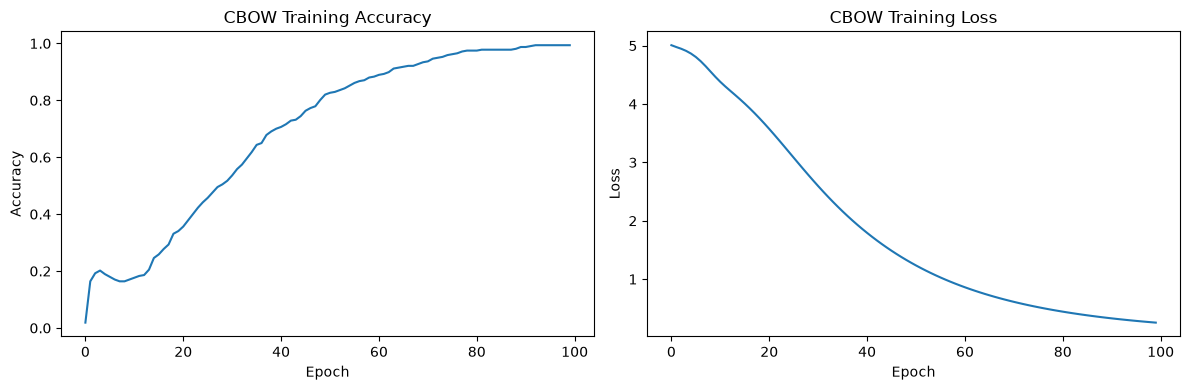

In [13]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"])
plt.title("CBOW Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"])
plt.title("CBOW Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

In [14]:
weights = cbow.get_weights()[0]

weights = weights[1:]

embedding_df = pd.DataFrame(
    weights,
    index=[id2word[i] for i in range(1, vocab_size)]
)

print("Embedding matrix shape:", weights.shape)

display(embedding_df.head(5))

Embedding matrix shape: (149, 100)


,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
the,0.283643,-0.289196,-0.172624,-0.539097,-0.454739,0.374854,-0.578092,-0.674116,0.025864,-0.716368,...,0.680157,0.123474,-0.262437,-0.680795,0.902417,-0.515637,-0.288284,-0.111470,0.760835,-0.744566
words,-0.698293,-0.665334,-0.342349,-0.067535,0.637608,-0.317377,0.603550,0.403331,-0.831650,-0.113045,...,0.734033,0.735604,-0.036015,-0.633624,-0.113393,-0.823510,0.287143,-0.690208,-0.065105,-0.125992
a,-0.307202,-1.104918,0.728193,-0.122763,-0.697476,-0.316485,-0.651837,0.413828,-0.131296,0.292975,...,0.422837,0.742456,-0.147833,0.029712,-0.690539,-0.364233,0.403112,0.024364,1.048226,-0.823223
is,0.888987,0.281074,-0.324735,0.504806,0.562407,0.551916,0.337468,0.389223,-0.538245,0.103800,...,0.062335,-0.063065,-0.142966,-0.038149,0.242080,-0.645531,-0.204501,-0.051225,0.606226,0.486289
word,0.333985,-1.013499,0.169778,0.613886,-0.076430,0.156150,-0.070295,-0.954403,-1.087840,0.429598,...,0.389067,-1.047544,0.329411,1.020150,0.142899,-0.758337,-0.323184,0.006796,0.340569,-0.025202


In [15]:
weights = cbow.get_weights()[0][1:]
distance_matrix = euclidean_distances(weights)

words = input("Enter words separated by spaces: ").lower().split()

for word in words:
    if word in word2id and word2id[word] != 0:
        word_index = word2id[word] - 1
        nearest_indices = distance_matrix[word_index].argsort()[1:6]

        similar_words = [id2word[idx + 1] for idx in nearest_indices]

        print(f"{word}: {similar_words}")
    else:
        print(f"{word}: Word not found in vocabulary.")

Enter words separated by spaces:  aads


aads: Word not found in vocabulary.


In [16]:
next_tokenizer = Tokenizer(oov_token="<OOV>")
next_tokenizer.fit_on_texts(data)
next_word2id = next_tokenizer.word_index
next_id2word = {i: w for w, i in next_word2id.items()}
next_vocab_size = len(next_word2id) + 1

input_sequences = []
for sentence in data:
    token_list = next_tokenizer.texts_to_sequences([sentence.lower()])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

max_sequence_len = max(len(seq) for seq in input_sequences)
padded_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre")

X_next = padded_sequences[:, :-1]
y_next = padded_sequences[:, -1]

print("Number of next-word training examples:", len(X_next))
print("Input shape:", X_next.shape)
print("Vocabulary size:", next_vocab_size)

Number of next-word training examples: 277
Input shape: (277, 9)
Vocabulary size: 151
